# Travaux Pratiques : Réseaux de Neurones Convolutifs (CNN)

**Objectifs :**
- Comprendre l'architecture et le fonctionnement des CNNs
- Implémenter et entraîner des modèles sur plusieurs datasets
- Évaluer et optimiser les performances
- Utiliser des techniques de régularisation et augmentation de données

---

##  Installation des dépendances

In [7]:
# Installer les packages nécessaires (si ce n'est pas déjà fait)
# !pip install tensorflow keras numpy matplotlib scikit-learn seaborn pandas

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Configuration d'affichage
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

print("✓ Toutes les dépendances sont chargées")
print(f"TensorFlow version: {tf.__version__}")

✓ Toutes les dépendances sont chargées
TensorFlow version: 2.19.0


---

# EXERCICE 1 : CNN sur les chiffres colorisés (Colored MNIST)

## Contexte
MNIST est un dataset classique de chiffres manuscrits en niveaux de gris (28×28 pixels). 
Nous allons le transformer en images colorisées (RGB) pour augmenter la complexité et tester 
la capacité du CNN à extraire des caractéristiques dans le domaine couleur.

## Étape 1 : Charger et coloriser le dataset

In [8]:
def colorize_mnist():
    """
    Transformer les images MNIST en niveaux de gris en images RGB colorisées (Vraies couleurs)
    """
    # 1. Charger MNIST depuis keras.datasets.mnist
    (x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

    # 2. Normaliser les images entre 0 et 1
    x_train = x_train.astype('float32') / 255.0
    x_test = x_test.astype('float32') / 255.0

    # 3. Redimensionner les images de 28x28 à 32x32 (utiliser tf.image.resize)
    # Expand dims to (N, 28, 28, 1)
    x_train = np.expand_dims(x_train, axis=-1)
    x_test = np.expand_dims(x_test, axis=-1)
    
    x_train = tf.image.resize(x_train, [32, 32]).numpy()
    x_test = tf.image.resize(x_test, [32, 32]).numpy()

    # 4. Coloriser aléatoirement
    # Générer une couleur aléatoire (R, G, B) pour chaque image
    # Shape: (N, 1, 1, 3)
    n_train = x_train.shape[0]
    n_test = x_test.shape[0]
    
    # On prend des couleurs avec une intensité min de 0.2 pour éviter d'avoir du noir invisible
    colors_train = np.random.uniform(0.2, 1.0, (n_train, 1, 1, 3))
    colors_test = np.random.uniform(0.2, 1.0, (n_test, 1, 1, 3))
    
    # Multiplication (Broadcasting): Image (N, 32, 32, 1) * Couleur (N, 1, 1, 3) -> (N, 32, 32, 3)
    x_train_colored = x_train * colors_train
    x_test_colored = x_test * colors_test

    return (x_train_colored, y_train), (x_test_colored, y_test)

# Charger et coloriser
(x_train_mnist, y_train_mnist), (x_test_mnist, y_test_mnist) = colorize_mnist()

print(f"✓ Données colorisées (Vraies Couleurs) chargées")
print(f"  - Train shape: {x_train_mnist.shape}")
print(f"  - Test shape: {x_test_mnist.shape}")
print(f"  - Values range: [{x_train_mnist.min():.2f}, {x_train_mnist.max():.2f}]")

✓ Données colorisées (Vraies Couleurs) chargées
  - Train shape: (60000, 32, 32, 3)
  - Test shape: (10000, 32, 32, 3)
  - Values range: [0.00, 1.00]


## Étape 2 : Visualiser les images colorisées

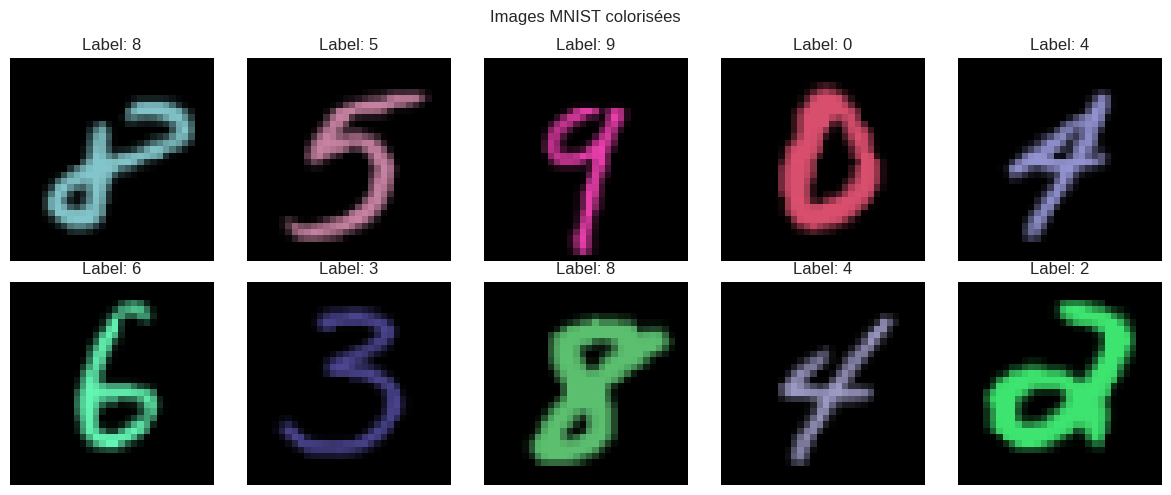

In [9]:
# Afficher 10 images colorisées aléatoires
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
indices = np.random.choice(len(x_train_mnist), 10, replace=False)

for idx, ax_idx in enumerate(range(10)):
    ax = axes[ax_idx // 5, ax_idx % 5]
    ax.imshow(x_train_mnist[indices[idx]])
    ax.set_title(f"Label: {y_train_mnist[indices[idx]]}")
    ax.axis('off')

plt.suptitle('Images MNIST colorisées')
plt.tight_layout()
plt.show()

## Étape 3 : Construire l'architecture CNN

In [10]:
def build_cnn_colored_mnist():
    """
    Construire un CNN pour classifier les chiffres colorisés
    """
    model = models.Sequential([
        layers.Input(shape=(32, 32, 3)),
        layers.Conv2D(32, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(64, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),
        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.Dropout(0.5),
        layers.Dense(10, activation='softmax')
    ])
    
    model.compile(optimizer='adam',
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    
    return model

model_ex1 = build_cnn_colored_mnist()
model_ex1.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       295,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 315,722 (1.20 MB)

 Trainable params: 315,722 (1.20 MB)

 Non-trainable params: 0 (0.00 B)

## Étape 4 : Entraîner le modèle

In [22]:
history_ex1 = model_ex1.fit(
    x_train_mnist, y_train_mnist,
    epochs=20,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

Epoch 1/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9958 - loss: 0.0123 - val_accuracy: 0.9910 - val_loss: 0.0642
Epoch 2/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.9948 - loss: 0.0167 - val_accuracy: 0.9908 - val_loss: 0.0560
Epoch 3/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.9958 - loss: 0.0133 - val_accuracy: 0.9913 - val_loss: 0.0593
Epoch 4/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.9968 - loss: 0.0112 - val_accuracy: 0.9914 - val_loss: 0.0518
Epoch 5/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.9964 - loss: 0.0118 - val_accuracy: 0.9920 - val_loss: 0.0510
Epoch 6/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.9964 - loss: 0.0112 - val_accuracy: 0.9903 - val_loss: 0.0596
Epoch 7/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.9962 - loss: 0.0122 - val_accuracy: 0.9923 - val_loss: 0.0633
Epoch 8/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9968 - loss: 0.0101 - 

## Étape 5 : Évaluation

In [12]:
test_loss, test_acc = model_ex1.evaluate(x_test_mnist, y_test_mnist)
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9892 - loss: 0.0520
Test Loss: 0.0401
Test Accuracy: 0.9917


## Étape 6 : Visualisation des résultats

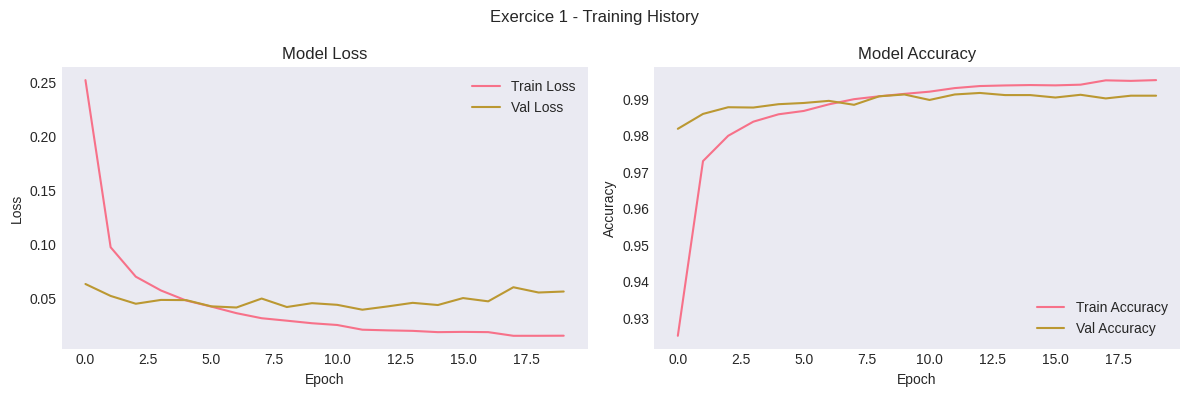

In [13]:
def plot_training_history(history, title="Training History"):
    """
    Tracer les courbes d'entraînement (loss et accuracy)
    """
    if history is None:
        print("Pas d'historique d'entraînement disponible")
        return
    
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    
    # Plot Loss
    axes[0].plot(history.history['loss'], label='Train Loss')
    axes[0].plot(history.history['val_loss'], label='Val Loss')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Loss')
    axes[0].set_title('Model Loss')
    axes[0].legend()
    axes[0].grid()
    
    # Plot Accuracy
    axes[1].plot(history.history['accuracy'], label='Train Accuracy')
    axes[1].plot(history.history['val_accuracy'], label='Val Accuracy')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Accuracy')
    axes[1].set_title('Model Accuracy')
    axes[1].legend()
    axes[1].grid()
    
    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

plot_training_history(history_ex1, "Exercice 1 - Training History")

## Questions de réflexion

1. Quelle est la précision du modèle ? Est-elle meilleure/pire que MNIST en niveaux de gris ?
2. Observer le graphique de loss. Y a-t-il de l'overfitting ?
3. Le dropout réduit-il l'écart entre train et validation ?
4. Quels chiffres sont les plus difficiles à classer ensemble ?

---

# EXERCICE 2 : CNN sur CIFAR-10 (Images naturelles)

## Contexte
CIFAR-10 : 60,000 images 32×32 en couleur réparties en 10 classes :
- Avions, automobiles, oiseaux, chats, cerfs, chiens, grenouilles, chevaux, navires, camions

C'est un défi bien plus difficile que MNIST !

## Étape 1 : Charger et explorer le dataset

In [14]:
# 1. Charger CIFAR-10
(x_train_cifar, y_train_cifar), (x_test_cifar, y_test_cifar) = keras.datasets.cifar10.load_data()

# 2. Normaliser entre 0 et 1
x_train_cifar = x_train_cifar.astype('float32') / 255.0
x_test_cifar = x_test_cifar.astype('float32') / 255.0

# 3. Aplatir les labels (actuellement shape [60000, 1])
y_train_cifar = y_train_cifar.flatten()
y_test_cifar = y_test_cifar.flatten()

# Informations sur le dataset
cifar_classes = ['airplane', 'automobile', 'bird', 'cat', 'deer', 
                 'dog', 'frog', 'horse', 'ship', 'truck']

print(f"Train shape: {x_train_cifar.shape}")
print(f"Test shape: {x_test_cifar.shape}")
print(f"Classes: {cifar_classes}")

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 7s 0us/step
Train shape: (50000, 32, 32, 3)
Test shape: (10000, 32, 32, 3)
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


## Étape 2 : Visualiser quelques images

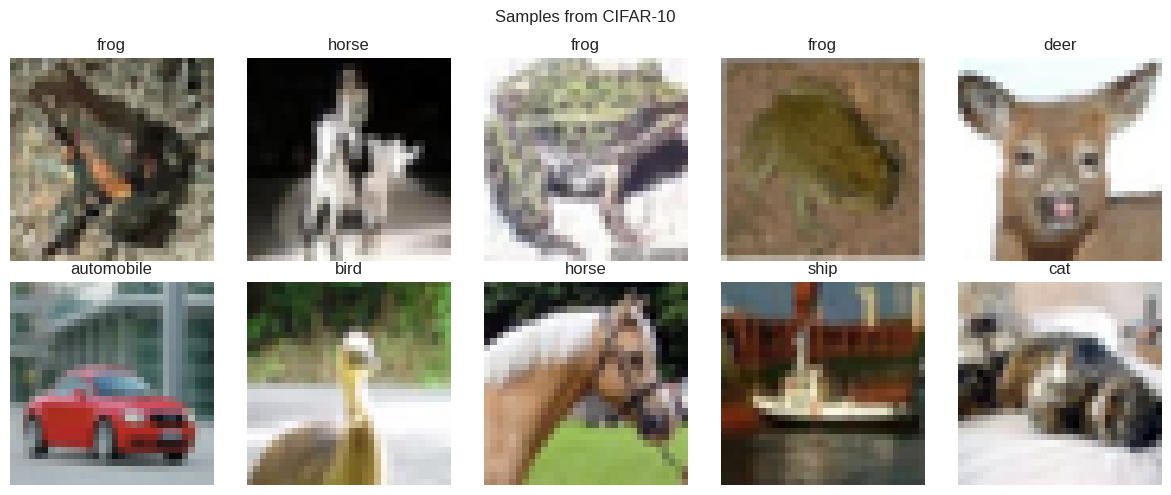

In [24]:
# Afficher 10 images aléatoires de CIFAR-10
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
indices = np.random.choice(len(x_train_cifar), 10, replace=False)

for idx, ax_idx in enumerate(range(10)):
    ax = axes[ax_idx // 5, ax_idx % 5]
    i = indices[idx]
    ax.imshow(x_train_cifar[i])
    ax.set_title(cifar_classes[y_train_cifar[i]])
    ax.axis('off')

plt.suptitle('Samples from CIFAR-10')
plt.tight_layout()
plt.show()

## Étape 3 : Construire un modèle CNN simple

In [16]:
def build_cnn_cifar10_simple():
    """
    Construire un CNN simple pour CIFAR-10
    """
    model = models.Sequential([
        layers.Input(shape=(32, 32, 3)),
        
        # Bloc 1
        layers.Conv2D(32, (3, 3), padding='same'),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.MaxPooling2D((2, 2)),
        
        # Bloc 2
        layers.Conv2D(64, (3, 3), padding='same'),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.MaxPooling2D((2, 2)),
        
        # Bloc 3
        layers.Conv2D(128, (3, 3), padding='same'),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.MaxPooling2D((2, 2)),
        
        layers.Flatten(),
        layers.Dense(256, activation='relu'),
        layers.Dropout(0.4),
        layers.Dense(128, activation='relu'),
        layers.Dropout(0.3),
        layers.Dense(10, activation='softmax')
    ])
    
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    
    return model

model_ex2_simple = build_cnn_cifar10_simple()
model_ex2_simple.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 652,874 (2.49 MB)

 Trainable params: 652,426 (2.49 MB)

 Non-trainable params: 448 (1.75 KB)

## Étape 4 : Data Augmentation

In [17]:
def create_data_augmentation():
    """
    Créer un pipeline d'augmentation de données
    """
    data_augmentation = keras.Sequential([
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.1),
        layers.RandomTranslation(0.1, 0.1),
        layers.RandomZoom(0.2),
    ])
    
    return data_augmentation

data_aug = create_data_augmentation()
print("✓ Data augmentation configurée")

✓ Data augmentation configurée


## Étape 5 : Visualiser l'augmentation de données

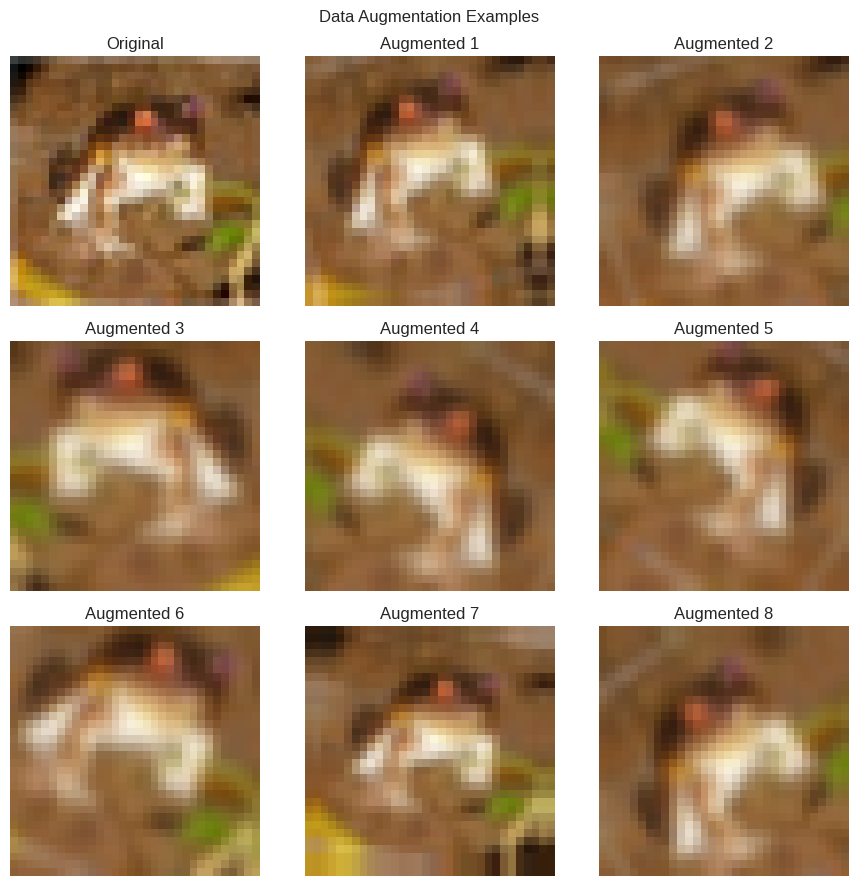

In [18]:
# Montrer une image original + 8 versions augmentées
data_aug = create_data_augmentation()
original_image = x_train_cifar[0]

fig, axes = plt.subplots(3, 3, figsize=(9, 9))
for i, ax in enumerate(axes.flat):
    if i == 0:
        ax.imshow(original_image)
        ax.set_title('Original')
    else:
        # Add batch dim, apply aug, remove batch dim
        augmented = data_aug(tf.expand_dims(original_image, 0), training=True)[0]
        ax.imshow(augmented)
        ax.set_title(f'Augmented {i}')
    ax.axis('off')

plt.suptitle('Data Augmentation Examples')
plt.tight_layout()
plt.show()

## Étape 6 : Entraîner sans augmentation

In [19]:
early_stop = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

history_ex2_simple = model_ex2_simple.fit(
    x_train_cifar, y_train_cifar,
    validation_split=0.2,
    epochs=30,
    batch_size=64,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 11s 8ms/step - accuracy: 0.2819 - loss: 2.0053 - val_accuracy: 0.4950 - val_loss: 1.4125
Epoch 2/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.4917 - loss: 1.3827 - val_accuracy: 0.5877 - val_loss: 1.1628
Epoch 3/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.5801 - loss: 1.1699 - val_accuracy: 0.6139 - val_loss: 1.1888
Epoch 4/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.6213 - loss: 1.0635 - val_accuracy: 0.4436 - val_loss: 1.6899
Epoch 5/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.6608 - loss: 0.9744 - val_accuracy: 0.6394 - val_loss: 1.0905
Epoch 6/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.6761 - loss: 0.9146 - val_accuracy: 0.5930 - val_loss: 1.1232
Epoch 7/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.7015 - loss: 0.8459 - val_accuracy: 0.6160 - val_loss: 1.1114
Epoch 8/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.7097 - loss: 0.8167 - val_accuracy: 0

## Étape 7 : Évaluation du modèle simple

Test Loss: 0.7810
Test Accuracy: 0.7518


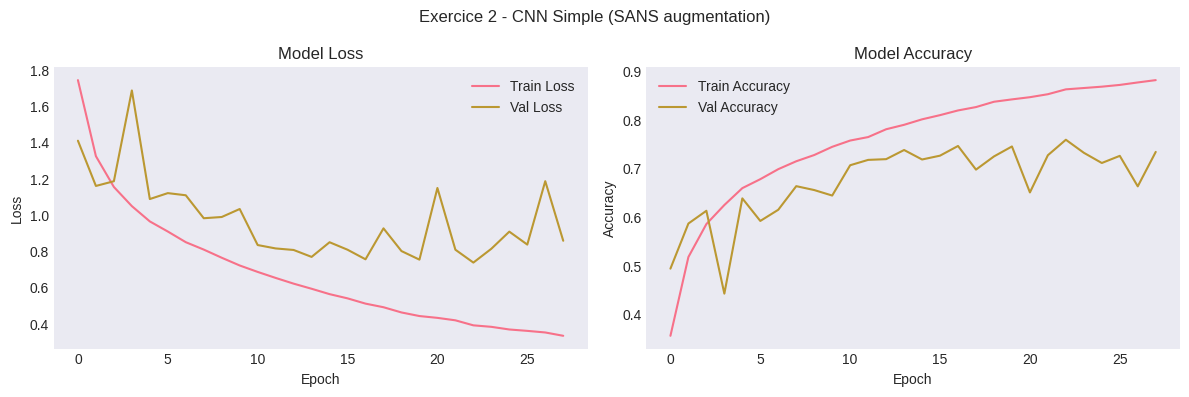

In [20]:
test_loss, test_acc = model_ex2_simple.evaluate(x_test_cifar, y_test_cifar, verbose=0)
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")

# Visualiser les courbes
plot_training_history(history_ex2_simple, "Exercice 2 - CNN Simple (SANS augmentation)")

## Étape 8 : Matrice de confusion

In [28]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

def plot_confusion_matrix(y_true, y_pred, classes, title='Matrice de Confusion', cmap=plt.cm.Blues):
    """
    Cette fonction affiche et trace la matrice de confusion.
    """
    # Calculer la matrice de confusion
    cm = confusion_matrix(y_true, y_pred)
    
    # Tracer la heatmap
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt='d', cmap=cmap, cbar=False,
                xticklabels=classes, yticklabels=classes)
    
    plt.title(title)
    plt.ylabel('Vraie étiquette')
    plt.xlabel('Étiquette prédite')
    plt.xticks(rotation=45)
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()
    
    # Afficher également le rapport de classification
    print("\nRapport de Classification :\n")
    print(classification_report(y_true, y_pred, target_names=classes))

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


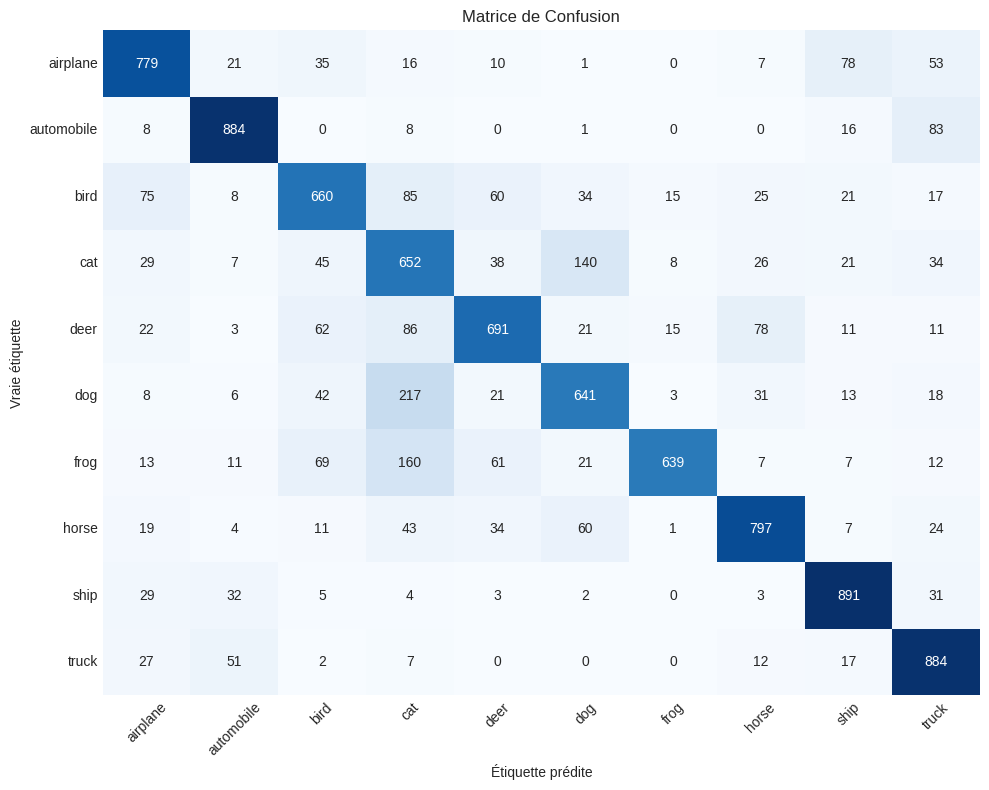


Rapport de Classification :

              precision    recall  f1-score   support

    airplane       0.77      0.78      0.78      1000
  automobile       0.86      0.88      0.87      1000
        bird       0.71      0.66      0.68      1000
         cat       0.51      0.65      0.57      1000
        deer       0.75      0.69      0.72      1000
         dog       0.70      0.64      0.67      1000
        frog       0.94      0.64      0.76      1000
       horse       0.81      0.80      0.80      1000
        ship       0.82      0.89      0.86      1000
       truck       0.76      0.88      0.82      1000

    accuracy                           0.75     10000
   macro avg       0.76      0.75      0.75     10000
weighted avg       0.76      0.75      0.75     10000



In [29]:
y_pred = model_ex2_simple.predict(x_test_cifar).argmax(axis=1)
plot_confusion_matrix(y_test_cifar, y_pred, cifar_classes)

## Étape 9 : Construire un modèle plus complexe

In [ ]:
def build_cnn_cifar10_complex():
    """
    Construire un CNN plus complexe pour CIFAR-10
    """
    model = models.Sequential([
        layers.Input(shape=(32, 32, 3)),
        
        # Bloc 1
        layers.Conv2D(64, (3, 3), padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.Conv2D(64, (3, 3), padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.25),
        
        # Bloc 2
        layers.Conv2D(128, (3, 3), padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.Conv2D(128, (3, 3), padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.25),
        
        # Bloc 3
        layers.Conv2D(256, (3, 3), padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.Conv2D(256, (3, 3), padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.25),
        
        layers.Flatten(),
        layers.Dense(512, activation='relu'),
        layers.Dropout(0.5),
        layers.Dense(256, activation='relu'),
        layers.Dropout(0.4),
        layers.Dense(10, activation='softmax')
    ])
    
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    
    return model

model_ex2_complex = build_cnn_cifar10_complex()
model_ex2_complex.summary()

## Étape 10 : Entraîner avec augmentation de données

In [ ]:
data_aug = create_data_augmentation()

# Utilisation de tf.data pour l'augmentation efficace
train_dataset = tf.data.Dataset.from_tensor_slices((x_train_cifar, y_train_cifar))
train_dataset = train_dataset.shuffle(buffer_size=1024).batch(32)
train_dataset = train_dataset.map(lambda x, y: (data_aug(x, training=True), y), num_parallel_calls=tf.data.AUTOTUNE)
train_dataset = train_dataset.prefetch(buffer_size=tf.data.AUTOTUNE)

val_dataset = tf.data.Dataset.from_tensor_slices((x_test_cifar, y_test_cifar))
val_dataset = val_dataset.batch(32).prefetch(buffer_size=tf.data.AUTOTUNE)

early_stop = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

history_ex2_complex = model_ex2_complex.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=50,
    callbacks=[early_stop],
    verbose=1
)

## Étape 11 : Comparaison des deux modèles

In [ ]:
test_loss_simple, test_acc_simple = model_ex2_simple.evaluate(x_test_cifar, y_test_cifar, verbose=0)
test_loss_complex, test_acc_complex = model_ex2_complex.evaluate(x_test_cifar, y_test_cifar, verbose=0)

print("\n=== COMPARAISON ===")
print(f"Simple - Test Accuracy: {test_acc_simple:.4f} (Loss: {test_loss_simple:.4f})")
print(f"Complex - Test Accuracy: {test_acc_complex:.4f} (Loss: {test_loss_complex:.4f})")

print(f"\nParamètres:")
print(f"Simple: {model_ex2_simple.count_params():,}")
print(f"Complex: {model_ex2_complex.count_params():,}")

# Graphique comparatif
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
if history_ex2_simple and history_ex2_complex:
    axes[0].plot(history_ex2_simple.history['val_accuracy'], label='Simple')
    axes[0].plot(history_ex2_complex.history['val_accuracy'], label='Complex')
    axes[0].set_title('Validation Accuracy Comparison')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Accuracy')
    axes[0].legend()
    axes[0].grid()
    
    axes[1].plot(history_ex2_simple.history['val_loss'], label='Simple')
    axes[1].plot(history_ex2_complex.history['val_loss'], label='Complex')
    axes[1].set_title('Validation Loss Comparison')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Loss')
    axes[1].legend()
    axes[1].grid()
plt.tight_layout()
plt.show()

## Questions de réflexion

1. Batch Normalization améliore-t-elle la convergence ?
2. Quel impact a l'augmentation de données sur l'overfitting ?
3. Quelles classes sont confondues ? Pourquoi ?
4. Comment pourriez-vous améliorer davantage la performance ?

---

# EXERCICE 3 : Transfer Learning

## Contexte
Le transfer learning consiste à réutiliser un modèle pré-entraîné sur ImageNet.
Cela permet d'obtenir de meilleures performances avec un entraînement plus court.

## Étape 1 : Charger un modèle pré-entraîné

In [ ]:
def build_transfer_learning_model(freeze_base=True):
    """
    Construire un modèle avec transfer learning
    """
    # Charger le modèle pré-entraîné
    base_model = keras.applications.MobileNetV2(
        input_shape=(32, 32, 3),
        include_top=False,
        weights='imagenet'
    )
    
    if freeze_base:
        base_model.trainable = False
    
    # Construire le modèle complet
    model = models.Sequential([
        base_model,
        layers.GlobalAveragePooling2D(),
        layers.Dense(256, activation='relu'),
        layers.Dropout(0.3),
        layers.Dense(10, activation='softmax')
    ])
    
    # Compiler
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    
    return model, base_model

model_ex3, base_model_ex3 = build_transfer_learning_model()
model_ex3.summary()

## Étape 2 : Phase 1 - Entraîner uniquement la tête

In [ ]:
early_stop = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

history_ex3_phase1 = model_ex3.fit(
    x_train_cifar, y_train_cifar,
    validation_split=0.2,
    epochs=10,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

test_loss_phase1, test_acc_phase1 = model_ex3.evaluate(x_test_cifar, y_test_cifar, verbose=0)
print(f"\nPhase 1 - Test Accuracy: {test_acc_phase1:.4f}")

## Étape 3 : Phase 2 - Fine-tuning des dernières couches

In [ ]:
base_model_ex3.trainable = True

# Geler les N premières couches (garder les features bas niveau)
num_to_freeze = len(base_model_ex3.layers) - 20  # Dégeler les 20 dernières
for i, layer in enumerate(base_model_ex3.layers[:num_to_freeze]):
    layer.trainable = False

# Récompiler avec un learning rate plus faible
model_ex3.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-4),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

early_stop = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

history_ex3_phase2 = model_ex3.fit(
    x_train_cifar, y_train_cifar,
    validation_split=0.2,
    epochs=20,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

test_loss_phase2, test_acc_phase2 = model_ex3.evaluate(x_test_cifar, y_test_cifar, verbose=0)
print(f"\nPhase 2 - Test Accuracy: {test_acc_phase2:.4f}")

## Étape 4 : Comparaison - Transfer Learning vs CNN from scratch

In [ ]:
print("\n" + "="*50)
print("COMPARAISON FINALE")
print("="*50)

if 'test_acc_complex' in locals():
    print(f"CNN from scratch (Complex): {test_acc_complex:.4f}")
else:
    print("CNN from scratch (Complex): Not executed")

if 'test_acc_phase2' in locals():
    print(f"Transfer Learning (Phase 2): {test_acc_phase2:.4f}")

print(f"\nParamètres:")
if 'model_ex2_complex' in locals():
    print(f"CNN Complex: {model_ex2_complex.count_params():,}")
print(f"Transfer Learning: {model_ex3.count_params():,}")

print(f"\nTrain Status:")
print(f"CNN Complex: Entraîné from scratch")
print(f"Transfer Learning: Pré-entraîné sur ImageNet")

## Questions de réflexion

1. Pourquoi le transfer learning converge-t-il plus rapidement ?
2. Qu'apprend le réseau dans les couches profondes d'ImageNet ?
3. Quel est l'impact du fine-tuning progressif sur la performance ?
4. Vaut-il toujours la peine d'utiliser transfer learning ?

---

# EXERCICE 4 (BONUS) : Visualisation des caractéristiques apprises

## Visualiser les filtres de convolution

In [ ]:
def visualize_conv_filters(model, layer_index=0, figsize=(12, 8)):
    """
    Visualiser les filtres d'une couche de convolution
    """
    layer = model.layers[layer_index]
    filters = layer.get_weights()[0]  # shape: (height, width, in_channels, out_channels)
    
    # Normaliser
    min_val = filters.min()
    max_val = filters.max()
    filters = (filters - min_val) / (max_val - min_val + 1e-8)
    
    # Afficher
    num_filters = min(32, filters.shape[3])
    cols = 8
    rows = (num_filters + cols - 1) // cols
    
    fig, axes = plt.subplots(rows, cols, figsize=figsize)
    axes = axes.flatten() if num_filters > 1 else [axes]
    
    for i in range(num_filters):
        ax = axes[i]
        if filters.shape[2] == 3:  # RGB
            ax.imshow(filters[:, :, :, i])
        else:  # Single channel
            # Assuming the filters work on single channel or just visualizing 0th channel
            ax.imshow(filters[:, :, 0, i], cmap='gray')
        ax.axis('off')
        ax.set_title(f'Filter {i}')
    
    # Masquer les axes inutilisés
    for j in range(num_filters, len(axes)):
        axes[j].axis('off')
    
    plt.suptitle(f'Filters from layer: {layer.name} (shape: {filters.shape})')
    plt.tight_layout()
    plt.show()

# Visualiser les filtres du premier modèle CIFAR-10
if 'model_ex2_simple' in locals():
    # Check if first layer is conv, or look for first conv layer
    for i, layer in enumerate(model_ex2_simple.layers):
        if isinstance(layer, keras.layers.Conv2D):
            visualize_conv_filters(model_ex2_simple, layer_index=i)
            break

## Visualiser les feature maps

In [ ]:
def visualize_feature_maps(model, image, layer_index=0, figsize=(12, 8)):
    """
    Visualiser les feature maps générées par une couche
    """
    # Préparer l'image
    image_input = tf.expand_dims(image, 0)
    
    # Créer un modèle partiel
    intermediate_model = models.Model(
        inputs=model.input,
        outputs=model.layers[layer_index].output
    )
    
    # Obtenir les feature maps
    feature_maps = intermediate_model.predict(image_input, verbose=0)
    feature_maps = feature_maps[0]  # Retirer la dimension batch
    
    # Afficher
    num_maps = min(32, feature_maps.shape[2])
    cols = 8
    rows = (num_maps + cols - 1) // cols
    
    fig, axes = plt.subplots(rows, cols, figsize=figsize)
    axes = axes.flatten()
    
    for i in range(num_maps):
        ax = axes[i]
        ax.imshow(feature_maps[:, :, i], cmap='viridis')
        ax.axis('off')
        ax.set_title(f'Map {i}')
    
    # Masquer les axes inutilisés
    for j in range(num_maps, len(axes)):
        axes[j].axis('off')
    
    plt.suptitle(f'Feature Maps from {model.layers[layer_index].name}')
    plt.tight_layout()
    plt.show()

# Visualiser les feature maps d'une image de test
if 'model_ex2_simple' in locals() and 'x_test_cifar' in locals():
    test_image = x_test_cifar[0]
    # Find a conv layer deeper in the network
    conv_indices = [i for i, l in enumerate(model_ex2_simple.layers) if isinstance(l, keras.layers.Conv2D)]
    if len(conv_indices) > 1:
        visualize_feature_maps(model_ex2_simple, test_image, layer_index=conv_indices[1])

## Analyser les prédictions incorrectes

In [ ]:
# Afficher les images mal classées
if 'model_ex2_simple' in locals():
    y_pred = model_ex2_simple.predict(x_test_cifar).argmax(axis=1)
    incorrect_mask = y_pred != y_test_cifar
    incorrect_indices = np.where(incorrect_mask)[0]

    # Afficher les 12 premières erreurs
    fig, axes = plt.subplots(3, 4, figsize=(12, 9))
    for idx, ax in enumerate(axes.flat):
        if idx < len(incorrect_indices):
            img_idx = incorrect_indices[idx]
            ax.imshow(x_test_cifar[img_idx])
            true_class = cifar_classes[y_test_cifar[img_idx]]
            pred_class = cifar_classes[y_pred[img_idx]]
            ax.set_title(f'True: {true_class}\nPred: {pred_class}', color='red')
            ax.axis('off')
        else:
            ax.axis('off')

    plt.suptitle(f'Incorrect predictions (showing {min(12, len(incorrect_indices))} of {len(incorrect_indices)})')
    plt.tight_layout()
    plt.show()